# BIOMASS L2A forest height in 3D — for any site

Give a site (a name, a box, or a point and a radius). The notebook:

1. searches the **ESA MAAP catalogue** for the BIOMASS **L2A forest-height** products covering it;
2. downloads **only the part inside your site** (a crop, not the whole product);
3. picks one pass (or the best one automatically) and joins its frames;
4. fetches the **Copernicus DEM 30 m** (public, no login) for the relief;
5. draws the forest height draped on the terrain: a static picture (Matplotlib, saved as PNG) and an **interactive** view you can rotate (Plotly, saved as HTML).

**What you need**
- A MAAP account with a `CLIENT_SECRET` and an `OFFLINE_TOKEN` (the same ones used by notebook 01). The notebook asks for them with a hidden prompt, or reads `ESA_CLIENT_SECRET` / `ESA_OFFLINE_TOKEN` from the environment, or `~/credentials.txt`. They are kept in memory only.
- Python packages: `rasterio`, `shapely`, `pystac-client`, `requests`, `matplotlib`, `scipy`, `pandas`, `plotly` (the next cell installs what is missing).
- **No credentials?** If you already have cropped scenes from notebook 01 (for example `data/lope/scenes/`), set `LOCAL_SCENES_DIR` in the parameter cell and nothing is downloaded.

**How to use it.** Edit the parameter cell (Section 1), then *Restart kernel and run all*.

### What this cell does

This bootstrap cell checks whether each required Python module is importable. It installs only missing packages into the current kernel environment, then reports what happened. Running it first makes the rest of the notebook reproducible on a fresh environment; it does not download any BIOMASS data.


In [1]:
# Map import names to the package names expected by pip.
# Install only missing dependencies and fail loudly if pip cannot install them.
# Section 0 — packages (installs only what is missing)
import importlib.util, subprocess, sys
need = {"rasterio": "rasterio", "shapely": "shapely", "pystac_client": "pystac-client", "requests": "requests",
        "matplotlib": "matplotlib", "scipy": "scipy", "pandas": "pandas", "plotly": "plotly"}
missing = [pip for mod, pip in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("packages ok" if not missing else f"installed: {missing}")

installed: ['plotly']


## 1 — Parameters (the only cell you need to edit)

### Configuration guide

This is the notebook's user-facing configuration. The geographic inputs are mutually exclusive: use a named preset, provide a bounding box in `[west, south, east, north]` order, or provide a `(latitude, longitude)` centre together with a square half-size. The date interval and orbit options control the catalogue query and pass selection.

The rendering parameters control resolution, colour scaling, vertical exaggeration, camera angle, and whether intermediate quick-look maps are displayed. `LOCAL_SCENES_DIR` is the offline path: when it is set, existing cropped GeoTIFFs and metadata are reused and MAAP authentication/downloads are skipped.


In [2]:
# Geographic and temporal inputs are intentionally kept together so this is the only cell most users edit.
# ---------------- WHERE ----------------
SITE_NAME = "Lopé"          # a preset (Rabi, Mabounie, Lopé) or any name you like
BBOX = None                 # [west, south, east, north] in degrees. None = use the preset called SITE_NAME
CENTER = None               # alternative to BBOX: (latitude, longitude) of the centre, e.g. (-0.2, 11.6)
HALF_SIZE_KM = 20           # used with CENTER: half the side of the square, in km

# ---------------- WHEN / WHICH PASS ----------------
DATETIME = "2025-11-01/.."  # search window "start/end" ("/.." = until today)
PASS = "auto"               # "auto" = the pass that covers most of the site; or a date such as "2026-01-14"
ORBIT = None                # None, "ascending" or "descending" (restricts the choice above)

# ---------------- HOW TO DRAW ----------------
MODE = "terrain"            # "terrain": forest height as colour on the Copernicus terrain
                            # "canopy" : forest height itself as relief (no terrain)
VERT_EXAG = 4               # vertical exaggeration
VMAX = 50                   # top of the colour scale [m]
GRID_RES_DEG = 0.0008       # grid step in degrees (about 90 m); enlarged automatically for big sites
MAX_PIXELS = 900            # longest side of the grid, to keep the figures light
ELEV, AZIM = 30, -95        # camera of the static picture (degrees)
SHOW_QUICKLOOK = True       # small maps of every pass found, to help choosing

# ---------------- FILES ----------------
DATA_DIR = "data/viewer"          # downloaded crops are stored here (one folder per site), so a second run is fast
OUT_DIR = "results/viewer"        # pictures and the interactive page
LOCAL_SCENES_DIR = None           # e.g. "data/lope/scenes": use crops that already exist, no login, no download
CATALOG_URL = "https://catalog.maap.eo.esa.int/catalogue/"

### Why the home directory is inspected

The helper functions look for optional credential files under the current user's home directory. This small diagnostic confirms which home directory the kernel sees, which is useful when the notebook is run from a remote Jupyter server or a different environment than the user's shell.


In [3]:
# Resolve the current user's home directory for the optional credential lookup performed later.
from pathlib import Path
f = Path.home()
print(f"home directory: {f}")

home directory: /home/alexia


### Helper layer

The functions below form the data-access and raster-processing layer:

- `find_scenes` queries the MAAP STAC catalogue and extracts the product metadata and asset URLs needed later.
- `get_esa_access_token` exchanges a long-lived offline token for a short-lived access token without printing or persisting secrets.
- `crop_remote` uses GDAL/rasterio HTTP access and a geometry transformed to the source CRS to read only the requested area.
- `save_geotiff` and `download_scenes` cache cropped scenes and a JSON sidecar so reruns do not repeat successful downloads.
- `to_grid` reprojects every raster onto one common north-up WGS84 grid.
- `fetch_dem` builds the same grid from Copernicus DEM tiles, allowing terrain and forest-height arrays to be plotted together.

The functions deliberately keep catalogue discovery, authenticated downloads, reprojection, and visualisation separate so each stage can be inspected or reused independently.


In [4]:
# Import scientific, geospatial, authentication, and display utilities used by the helper functions below.
# Work internally in WGS84 because the catalogue query and user-provided bounds use longitude/latitude.
# Section 2 — helpers (catalogue, authentication, crop, grid, terrain)
import json, os, re, time, warnings
from pathlib import Path
from getpass import getpass
import numpy as np
import pandas as pd
import rasterio
import requests
from rasterio.enums import Resampling
from rasterio.mask import mask
from rasterio.transform import from_origin
from rasterio.warp import reproject, transform_geom
from rasterio.crs import CRS
from shapely.geometry import box, mapping
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
WGS84 = CRS.from_epsg(4326)

PRESETS = {  # the three LiDAR sites of the hackathon project (Gabon)
    "Rabi": [9.59494, -2.29494, 10.2766, -1.68464],
    "Mabounie": [9.93509, -0.950969, 10.7425, -0.679589],
    "Lopé": [11.39674, -0.64224, 12.02394, -0.01559],
}

def find_scenes(bbox, datetime, catalog_url, collection="BiomassLevel2a") -> pd.DataFrame:
    """All BIOMASS L2A forest-height products that intersect bbox (one row each)."""
    from pystac_client import Client
    rows = []
    for it in Client.open(catalog_url).search(collections=[collection], bbox=bbox, datetime=datetime,
                                              max_items=300, method="GET").items():
        if not it.id.startswith("BIO_FP_FH__L2A"):
            continue
        tf = re.search(r"_T(\d+)_F(\d+)_", it.id)
        rows.append(dict(
            id=it.id, date=pd.Timestamp(it.properties.get("start_datetime") or it.datetime).tz_localize(None).normalize(),
            track=int(tf.group(1)), frame=int(tf.group(2)), orbit=it.properties.get("sat:orbit_state", "?"),
            look=it.properties.get("sar:observation_direction", "left"), footprint=it.geometry["coordinates"][0],
            height_href=it.assets["enclosure_i_fh_tiff"].get_absolute_href(),
            quality_href=it.assets["enclosure_i_quality_tiff"].get_absolute_href()))
    return pd.DataFrame(rows).sort_values("date").reset_index(drop=True) if rows else pd.DataFrame()

def get_esa_access_token() -> str:
    """Short-lived MAAP token from the offline token. Secrets are never printed or written."""
    cred = {}
    f = Path.home() / "credentials.txt"
    if f.exists():
        for line in f.read_text(encoding="utf-8").splitlines():
            if "=" in line and not line.strip().startswith("#"):
                k, v = line.split("=", 1); cred[k.strip()] = v.strip()
    tf = Path.home() / "token.txt"
    if tf.exists() and "OFFLINE_TOKEN" not in cred:
        cred["OFFLINE_TOKEN"] = tf.read_text().strip()
    client_id = cred.get("CLIENT_ID") or os.environ.get("ESA_CLIENT_ID", "offline-token")
    secret = cred.get("CLIENT_SECRET") or os.environ.get("ESA_CLIENT_SECRET") or getpass("ESA MAAP CLIENT_SECRET (hidden): ")
    offline = cred.get("OFFLINE_TOKEN") or os.environ.get("ESA_OFFLINE_TOKEN") or getpass("ESA MAAP OFFLINE_TOKEN (hidden): ")
    r = requests.post("https://iam.maap.eo.esa.int/realms/esa-maap/protocol/openid-connect/token",
                      data=dict(client_id=client_id, client_secret=secret, grant_type="refresh_token",
                                refresh_token=offline, scope="offline_access openid"), timeout=45)
    r.raise_for_status()
    if not r.json().get("access_token"):
        raise RuntimeError("MAAP did not return an access token.")
    os.environ.setdefault("ESA_CLIENT_SECRET", secret); os.environ.setdefault("ESA_OFFLINE_TOKEN", offline)  # asked only once
    return r.json()["access_token"]

def crop_remote(url, bbox, token):
    """Read only the part of a remote GeoTIFF that lies inside bbox. NaN where there is no data."""
    with rasterio.Env(GDAL_HTTP_HEADERS=f"Authorization: Bearer {token}", GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
        with rasterio.open(url) as src:
            if src.crs is None:
                raise ValueError("remote GeoTIFF without CRS")
            roi = transform_geom("EPSG:4326", src.crs.to_string(), mapping(box(*bbox)))
            arr, tr = mask(src, [roi], crop=True, filled=False)
            return np.ma.filled(arr[0].astype("float64"), np.nan), tr, src.crs

def save_geotiff(path, arr, transform, crs):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    v = np.where(np.isfinite(arr), arr, -9999).astype("float32")
    with rasterio.open(path, "w", driver="GTiff", height=v.shape[0], width=v.shape[1], count=1, dtype="float32",
                       crs=crs, transform=transform, nodata=-9999, compress="deflate", predictor=3) as d:
        d.write(v, 1)

def scene_files(site_dir, sid):
    d = Path(site_dir) / "scenes"
    return d / f"{sid}_height.tif", d / f"{sid}.json"

def download_scenes(scenes, bbox, site_dir):
    """Crop the height of every scene that is not already on disk. A scene without valid pixels is recorded as empty."""
    todo = [s for _, s in scenes.iterrows() if not scene_files(site_dir, s.id)[1].exists()]
    print(f"{len(scenes)} scenes found, {len(todo)} to download")
    for s in todo:
        hp, mp = scene_files(site_dir, s.id)
        meta = dict(id=s.id, date=s.date.isoformat(), track=int(s.track), frame=int(s.frame), orbit=str(s.orbit))
        try:
            h, tr, crs = crop_remote(s.height_href, bbox, get_esa_access_token())
            h = np.where(h < 0, np.nan, h); n = int(np.isfinite(h).sum()); meta["valid_pixels"] = n
            if n:
                save_geotiff(hp, h, tr, crs)
            print(f"  {s.date.date()} T{s.track:03d} F{s.frame} {s.orbit[:4]}: {n:,} valid pixels")
        except Exception as err:        # one failing scene must not stop the others
            meta["error"] = f"{type(err).__name__}: {str(err)[:200]}"; print(f"  {s.id}: FAILED ({meta['error']})")
        mp.parent.mkdir(parents=True, exist_ok=True); mp.write_text(json.dumps(meta, indent=1)); time.sleep(0.5)

def to_grid(path, bbox, res, resampling=Resampling.average):
    """Any raster (local file or URL) on a north-up lon/lat grid that covers bbox = [W, S, E, N]."""
    W, S, E, N = bbox; w, h = int(round((E - W) / res)), int(round((N - S) / res))
    out = np.full((h, w), np.nan, "float32")
    with rasterio.open(path) as src:
        reproject(rasterio.band(src, 1), out, src_crs=src.crs or WGS84, src_nodata=src.nodata,
                  dst_transform=from_origin(W, N, res, res), dst_crs=WGS84, resampling=resampling, dst_nodata=np.nan)
    return out

def tile_code(lat, lon):
    return ("N" if lat >= 0 else "S") + f"{abs(lat):02d}", ("E" if lon >= 0 else "W") + f"{abs(lon):03d}"

def fetch_dem(bbox, res):
    """Copernicus DEM GLO-30 (AWS open data, no login) on the same grid. None if nothing could be read."""
    W, S, E, N = bbox; out = None
    for lat in range(int(np.floor(S)), int(np.ceil(N))):
        for lon in range(int(np.floor(W)), int(np.ceil(E))):
            ns, ew = tile_code(lat, lon); name = f"Copernicus_DSM_COG_10_{ns}_00_{ew}_00_DEM"
            try:
                a = to_grid(f"https://copernicus-dem-30m.s3.amazonaws.com/{name}/{name}.tif", bbox, res)
            except Exception:
                continue                  # ocean tiles do not exist; a network error also lands here
            out = a if out is None else np.where(np.isfinite(a), a, out)
    return out
print("helpers ready")

helpers ready


## 2 — The site

### Resolving the area of interest

This cell converts the selected geographic input into one validated bounding box. A centre point is expanded approximately in degrees using the latitude-dependent longitudinal scale; a preset is used only when neither a box nor a centre was supplied. The bounds are then checked, a filesystem-safe slug is generated, and output directories are prepared.


In [5]:
# Build a square around the requested centre when a centre was supplied instead of an explicit box.
# Convert all bounds to floats before validating and passing them to geospatial libraries.
# Section 3 — resolve the site and make a folder name
if BBOX is None and CENTER is not None:
    lat0, lon0 = CENTER
    BBOX = [lon0 - HALF_SIZE_KM / (111.32 * np.cos(np.radians(lat0))), lat0 - HALF_SIZE_KM / 111.32,
            lon0 + HALF_SIZE_KM / (111.32 * np.cos(np.radians(lat0))), lat0 + HALF_SIZE_KM / 111.32]
if BBOX is None:
    if SITE_NAME not in PRESETS:
        raise ValueError(f"Unknown site {SITE_NAME!r}: set BBOX=[west, south, east, north] or CENTER=(lat, lon). Presets: {list(PRESETS)}")
    BBOX = PRESETS[SITE_NAME]
BBOX = [float(x) for x in BBOX]
W, S, E, N = BBOX
assert W < E and S < N and -180 <= W and E <= 180 and -90 <= S and N <= 90, "BBOX must be [west, south, east, north] in degrees"
LAT0 = (S + N) / 2
print(f"{SITE_NAME}: lon {W:.4f} to {E:.4f}, lat {S:.4f} to {N:.4f}  ({(E - W) * 111.32 * np.cos(np.radians(LAT0)):.0f} x {(N - S) * 111.32:.0f} km)")
if max(E - W, N - S) > 1.5:
    print("WARNING: a very large site. The grid is coarsened automatically, but the download and the figures will be heavy.")
if S > 75 or N < -56:
    print("NOTE: BIOMASS targets forests between 75°N and 56°S; products outside may not exist.")
import unicodedata
SLUG = re.sub(r"[^A-Za-z0-9]+", "_", unicodedata.normalize("NFKD", SITE_NAME).encode("ascii", "ignore").decode()).strip("_").lower() or "site"
SITE_DIR = Path(DATA_DIR) / SLUG; OUT = Path(OUT_DIR); OUT.mkdir(parents=True, exist_ok=True)

Lopé: lon 11.3967 to 12.0239, lat -0.6422 to -0.0156  (70 x 70 km)


## 3 — Search and download the L2A products

### Catalogue discovery versus offline mode

When no local directory is configured, the STAC search asks MAAP for BIOMASS Level-2A forest-height items intersecting the bounding box and date range. The result table exposes the acquisition date, orbit, track, frame, and product identifier so the available observations can be audited. In local mode, this network step is intentionally bypassed because the scene metadata is already on disk.


In [6]:
# Keep the catalogue result empty in local mode; later stages read the local metadata instead.
# Section 4 — catalogue search (skipped when you point to local crops)
SCENES = pd.DataFrame()
if LOCAL_SCENES_DIR:
    print("Using local crops from", LOCAL_SCENES_DIR, "(no search, no download)")
else:
    SCENES = find_scenes(BBOX, DATETIME, CATALOG_URL)
    if SCENES.empty:
        raise RuntimeError("No BIOMASS L2A forest-height product found for this site and period. Try a wider DATETIME, or check the site: "
                           "BIOMASS does not image North America and Europe, and L2A starts after the commissioning phase.")
    display(SCENES[["date", "orbit", "track", "frame", "id"]])

,date,orbit,track,frame,id
0,2025-12-15,ascending,4,1,BIO_FP_FH__L2A_20251215T050019_20251227T050047...
1,2025-12-15,ascending,3,310,BIO_FP_FH__L2A_20251215T050000_20251227T050028...
2,2026-01-14,ascending,4,1,BIO_FP_FH__L2A_20260114T050037_20260126T050104...
3,2026-01-14,ascending,3,310,BIO_FP_FH__L2A_20260114T050018_20260126T050045...
4,2026-02-13,descending,11,156,BIO_FP_FH__L2A_20260213T172108_20260225T172136...
5,2026-02-13,descending,11,155,BIO_FP_FH__L2A_20260213T172049_20260225T172117...
6,2026-02-13,ascending,4,1,BIO_FP_FH__L2A_20260213T050451_20260225T050518...
7,2026-02-13,ascending,3,310,BIO_FP_FH__L2A_20260213T050432_20260225T050459...
8,2026-04-26,descending,11,155,BIO_FP_FH__L2A_20260426T172529_20260508T172557...
9,2026-05-17,descending,11,156,BIO_FP_FH__L2A_20260517T172602_20260529T172629...


### Download and cache strategy

Each matching product is cropped to the area of interest before it is saved. The JSON sidecar is written even when a scene contains no valid pixels or fails, which records the attempted product and prevents an unchanged rerun from repeatedly requesting the same scene. A failure is reported per scene so one unavailable product does not discard all other usable acquisitions.


In [7]:
# Do not contact MAAP when the user has supplied pre-cropped local scenes.
# Section 5 — download only what is missing (a crop of every scene, saved in DATA_DIR)
if not LOCAL_SCENES_DIR:
    download_scenes(SCENES, BBOX, SITE_DIR)

12 scenes found, 12 to download
  2025-12-15 T004 F1 asce: 267,090 valid pixels
  2025-12-15 T003 F310 asce: 29,918 valid pixels
  2026-01-14 T004 F1 asce: 370,051 valid pixels
  2026-01-14 T003 F310 asce: 29,208 valid pixels
  2026-02-13 T011 F156 desc: 17,884 valid pixels
  2026-02-13 T011 F155 desc: 29,486 valid pixels
  2026-02-13 T004 F1 asce: 56,454 valid pixels
  2026-02-13 T003 F310 asce: 46,369 valid pixels
  2026-04-26 T011 F155 desc: 2,098 valid pixels
  2026-05-17 T011 F156 desc: 19 valid pixels
  2026-05-17 T011 F155 desc: 349,873 valid pixels
  2026-06-07 T011 F155 desc: 304,762 valid pixels


## 4 — Choose a pass

A **pass** is one date and one direction; a pass is often split into several **frames**, which are joined here.
Different passes see the same forest from different sides (ascending / descending) and on different days, so the 3D picture
changes with the choice. The quick-look below shows every pass found.

### Harmonising scenes and selecting a pass

All cached height rasters are resampled onto the same grid. Scenes with the same acquisition date and orbit are grouped into one pass; missing cells are filled from other frames, effectively mosaicking adjacent frames without overwriting already populated pixels.

The summary reports coverage and median height for every pass. If requested, quick-look maps make the spatial coverage visible. Finally, the candidates are filtered by `ORBIT` and `PASS`, and the remaining pass with the greatest valid-pixel coverage is selected for the final figures. Heights outside the expected 0--150 m range are treated as invalid before these statistics are computed.


grid step 89 m, 783 x 784 pixels


,date,orbit,frames,coverage,median_height
0,2025-12-15,ascending,2,48%,28.0 m
1,2026-01-14,ascending,2,66%,32.7 m
2,2026-02-13,ascending,2,16%,21.6 m
3,2026-02-13,descending,2,7%,20.1 m
4,2026-04-26,descending,1,0%,28.3 m
5,2026-05-17,descending,2,62%,31.5 m
6,2026-06-07,descending,1,54%,31.8 m


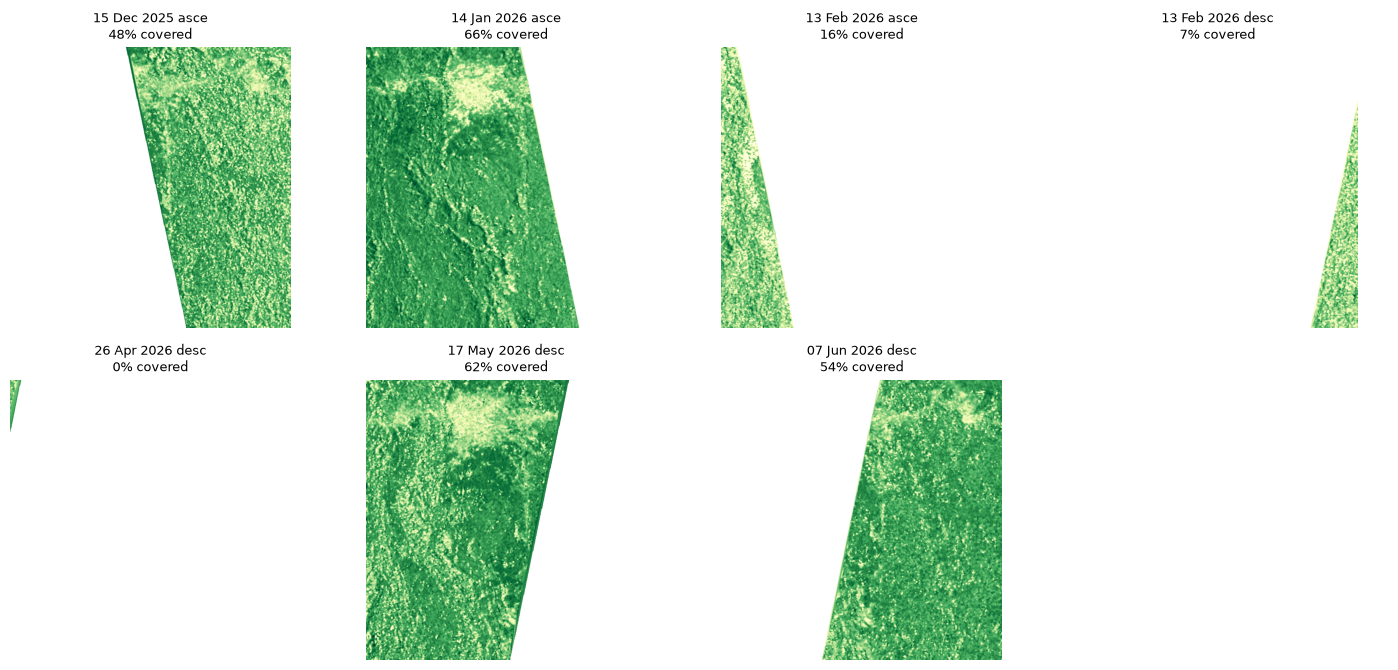

Chosen pass: 14 Jan 2026 ascending, 66% of the site, 2 frame(s)


In [8]:
# Use one common grid so scenes with different source CRSs, resolutions, or footprints can be compared.
# Increase the grid spacing for large sites to cap the longest dimension and keep memory use predictable.
# Accumulate frames into pass-level mosaics keyed by acquisition date and orbit direction.
# Section 6 — put every scene on the common grid, join the frames of each pass, choose
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LightSource, Normalize
SC_DIR = Path(LOCAL_SCENES_DIR) if LOCAL_SCENES_DIR else SITE_DIR / "scenes"
RES = GRID_RES_DEG
n_side = max((E - W) / RES, (N - S) / RES)
if n_side > MAX_PIXELS:
    RES = RES * n_side / MAX_PIXELS
H_ROWS, H_COLS = int(round((N - S) / RES)), int(round((E - W) / RES))
print(f"grid step {RES * 111320:.0f} m, {H_ROWS} x {H_COLS} pixels")

PASSES = {}
for mp in sorted(SC_DIR.glob("*.json")):
    meta = json.loads(mp.read_text()); hp = mp.with_name(f"{meta['id']}_height.tif")
    if not hp.exists() or meta.get("valid_pixels", 1) == 0:
        continue
    h = to_grid(hp, BBOX, RES); h[(h < 0) | (h > 150)] = np.nan
    if not np.isfinite(h).any():
        continue
    key = (pd.Timestamp(meta["date"]).normalize(), str(meta.get("orbit", "?")))
    if key not in PASSES:
        PASSES[key] = dict(h=h, frames=[meta["id"]])
    else:
        PASSES[key]["h"] = np.where(np.isfinite(PASSES[key]["h"]), PASSES[key]["h"], h); PASSES[key]["frames"].append(meta["id"])
if not PASSES:
    raise RuntimeError(f"No scene with valid pixels inside the site in {SC_DIR}. Check the site, the period, or the download messages above.")
for p in PASSES.values():
    p["coverage"] = float(np.isfinite(p["h"]).mean())
SUMMARY = pd.DataFrame([dict(date=f"{d:%Y-%m-%d}", orbit=o, frames=len(p["frames"]), coverage=f"{100 * p['coverage']:.0f}%",
                             median_height=f"{np.nanmedian(p['h']):.1f} m") for (d, o), p in sorted(PASSES.items())])
display(SUMMARY)

if SHOW_QUICKLOOK:
    keys = sorted(PASSES); n = len(keys); cols = min(n, 4); rows = int(np.ceil(n / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(3.6 * cols, 3.4 * rows), squeeze=False)
    for a in ax.ravel():
        a.axis("off")
    for a, k in zip(ax.ravel(), keys):
        a.imshow(PASSES[k]["h"], cmap="YlGn", vmin=0, vmax=VMAX, extent=[W, E, S, N]); a.set_title(f"{k[0]:%d %b %Y} {k[1][:4]}\n{100 * PASSES[k]['coverage']:.0f}% covered", fontsize=9)
    fig.tight_layout(); plt.show()

cand = {k: p for k, p in PASSES.items() if ORBIT is None or k[1].lower().startswith(ORBIT.lower()[:4])}
if PASS != "auto":
    cand = {k: p for k, p in cand.items() if f"{k[0]:%Y-%m-%d}" == str(PASS)}
if not cand:
    raise ValueError(f"No pass matches PASS={PASS!r}, ORBIT={ORBIT!r}. Available: {[f'{d:%Y-%m-%d} {o}' for d, o in sorted(PASSES)]}")
CHOSEN = max(cand, key=lambda k: cand[k]["coverage"])
HF = PASSES[CHOSEN]["h"]
print(f"Chosen pass: {CHOSEN[0]:%d %b %Y} {CHOSEN[1]}, {100 * PASSES[CHOSEN]['coverage']:.0f}% of the site, {len(PASSES[CHOSEN]['frames'])} frame(s)")
if PASSES[CHOSEN]["coverage"] < 0.05:
    print("WARNING: this pass covers very little of the site: the 3D picture will be mostly empty.")

## 5 — Terrain

### Choosing the surface geometry

In `terrain` mode, the Copernicus DEM supplies the z-coordinate while the BIOMASS forest height controls surface colour. Missing DEM cells are filled with the lowest available elevation so the mesh remains drawable. In `canopy` mode, the height raster itself becomes the z-coordinate, which produces a canopy-height relief rather than a terrain surface.


In [9]:
# The z-surface depends on the selected visualisation mode, while HF remains the colour variable.
# Section 7 — Copernicus DEM on the same grid (needs internet; no login)
Z = None
if MODE == "terrain":
    Z = fetch_dem(BBOX, RES)
    if Z is None or not np.isfinite(Z).any():
        print("WARNING: terrain could not be downloaded: drawing on a flat surface instead (check the internet connection).")
        Z = np.zeros((H_ROWS, H_COLS), "float32")
    else:
        Z = np.where(np.isfinite(Z), Z, np.nanmin(Z))          # missing tiles (sea) at the lowest level
        print(f"terrain: {np.nanmin(Z):.0f} to {np.nanmax(Z):.0f} m")
else:
    Z = np.nan_to_num(HF, nan=0.0)                          # canopy relief: the height itself

terrain: 88 to 926 m


## 6 — Static 3D picture

Colour = forest height (light = short, dark = tall); grey = no BIOMASS data. In `terrain` mode the surface is the Copernicus
DEM (a *surface* model: it already includes the canopy) exaggerated by `VERT_EXAG`.

### Static 3D rendering

This cell creates a publication-style PNG with Matplotlib. The forest-height array is mapped to a green colour ramp; invalid cells are darkened. A hillshade derived from the chosen z-surface modulates the colours to convey shape, while the mesh coordinates are converted from longitude/latitude to approximate kilometres relative to the south-west corner. The grid is strided for rendering efficiency, and the same vertical exaggeration is reflected in the 3D aspect ratio and title.


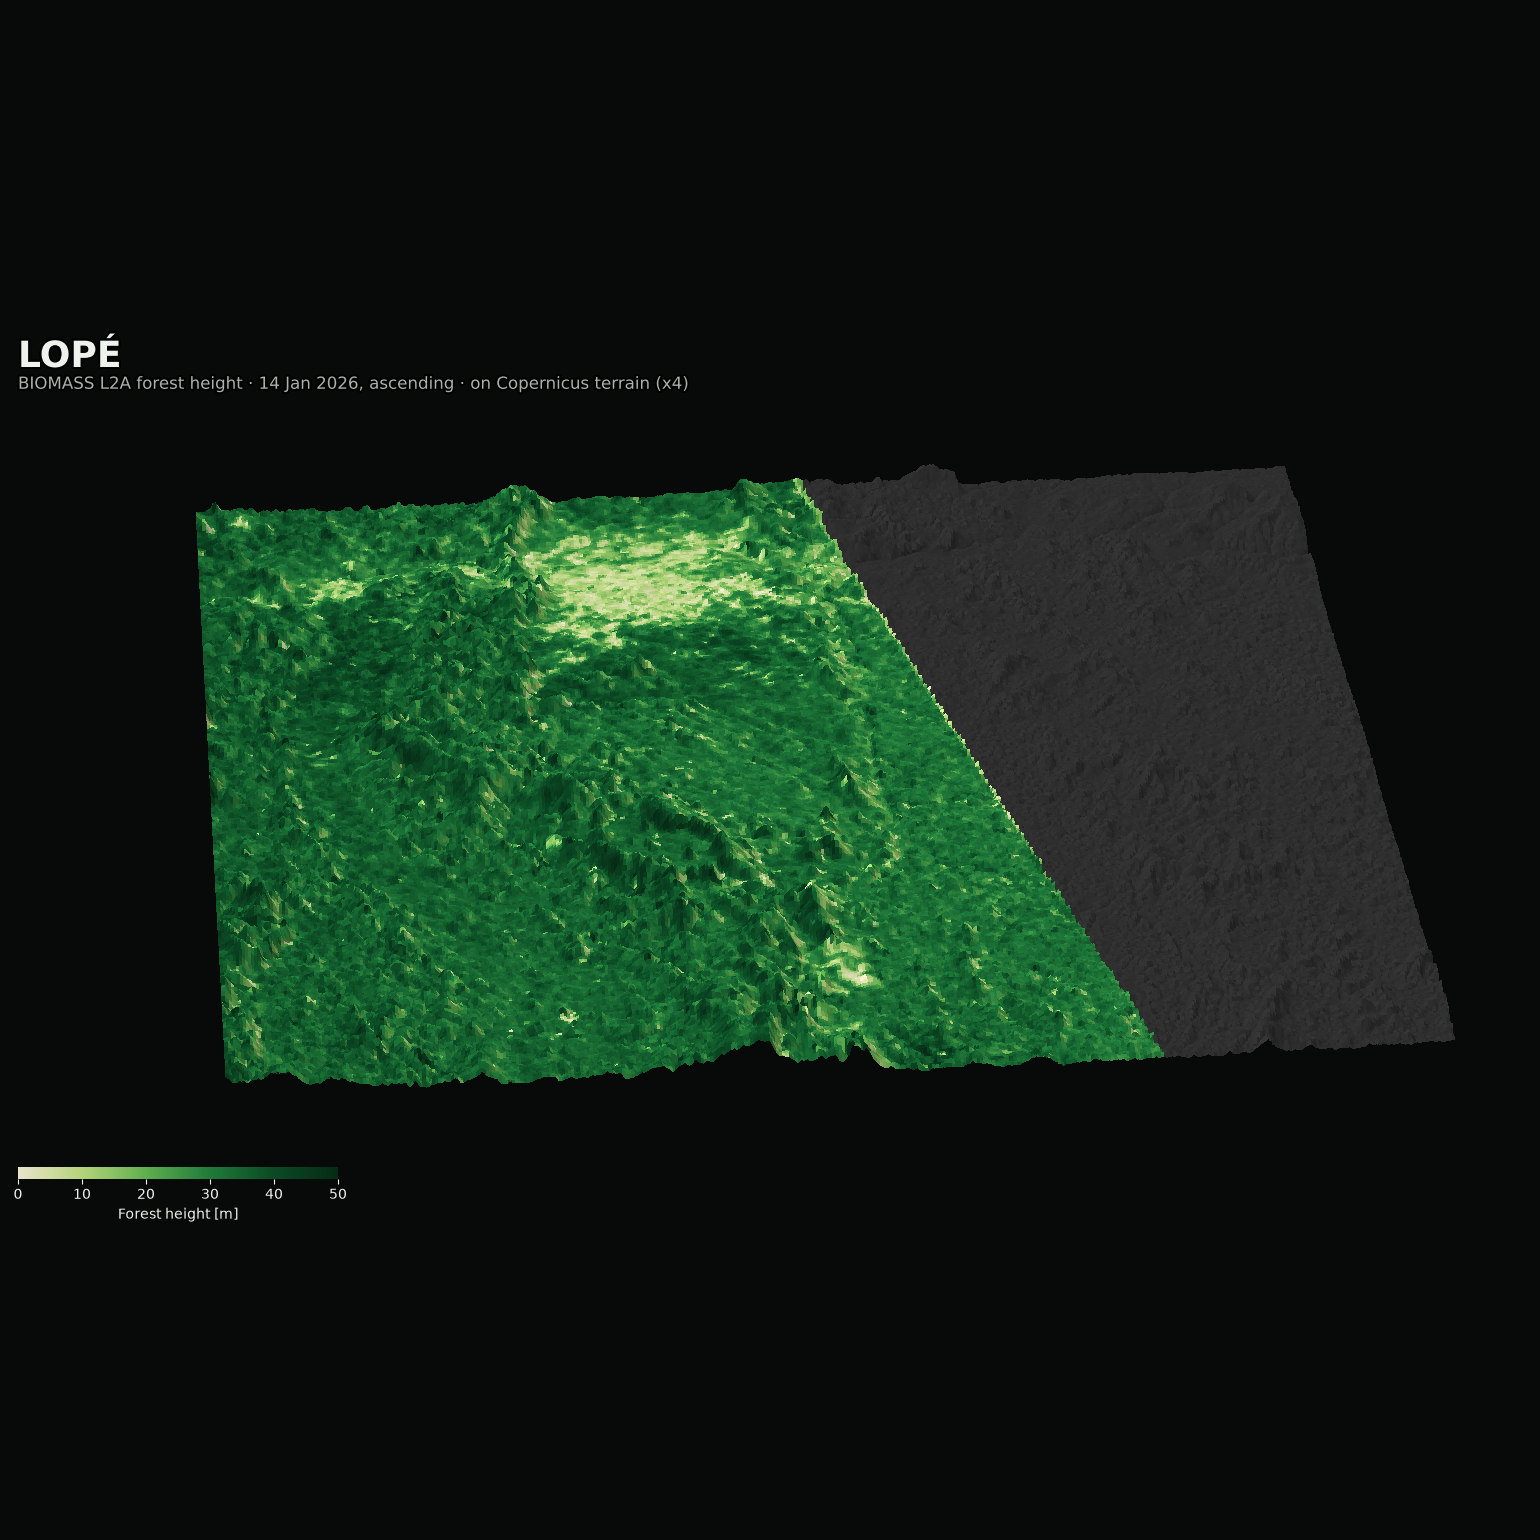

saved results/viewer/lope_20260114_asce_3d.png


In [10]:
# Define the shared forest-height colour ramp and the dark presentation palette.
# Convert geographic coordinates to local kilometre coordinates for a readable 3D axis.
# Combine colour and hillshade so the raster values remain visible while terrain shape is legible.
# Section 8 — static picture (Matplotlib)
import matplotlib.patheffects as pe
HEIGHT = LinearSegmentedColormap.from_list("height", ["#e9e4c9", "#b5d37a", "#5fae4e", "#1f7a3a", "#0b4a24", "#062b16"])
BG, FG, MUTED = "#070a08", "#eef2ec", "#a9b3a8"
GLOW = [pe.withStroke(linewidth=3, foreground="black")]
dx = RES * 111320 * np.cos(np.radians(LAT0)); dy = RES * 111320
LON, LAT = np.meshgrid(np.linspace(W, E, H_COLS), np.linspace(N, S, H_ROWS))
xk, yk = (LON - W) * 111.32 * np.cos(np.radians(LAT0)), (LAT - S) * 111.32

shade = LightSource(azdeg=300, altdeg=30).hillshade(Z, vert_exag=2, dx=dx, dy=dy)
col = HEIGHT(Normalize(0, VMAX)(np.nan_to_num(HF)))[..., :3]; col[~np.isfinite(HF)] = 0.18
col = np.clip(col * (0.55 + 0.65 * shade[..., None]), 0, 1)

stride = max(1, int(np.ceil(max(H_ROWS, H_COLS) / 450)))
zrange_km = max((np.nanmax(Z) - np.nanmin(Z)) / 1000, 1e-3)
fig = plt.figure(figsize=(16, 9.5), facecolor=BG)
ax = fig.add_axes([-0.2, -0.3, 1.4, 1.6], projection="3d", facecolor=BG)
ax.plot_surface(xk, yk, Z, facecolors=col, rstride=stride, cstride=stride, linewidth=0, antialiased=False, shade=False)
ax.set_box_aspect((xk.max(), yk.max(), zrange_km * VERT_EXAG), zoom=1.2)
ax.view_init(elev=ELEV, azim=AZIM); ax.set_axis_off()
fig.text(0.03, 0.96, SITE_NAME.upper(), color=FG, fontsize=26, fontweight="bold", va="top", path_effects=GLOW)
fig.text(0.03, 0.915, f"BIOMASS L2A forest height · {CHOSEN[0]:%d %b %Y}, {CHOSEN[1]} · "
         + (f"on Copernicus terrain (x{VERT_EXAG})" if MODE == "terrain" else f"as relief (x{VERT_EXAG})"),
         color=MUTED, fontsize=12, va="top", path_effects=GLOW)
cax = fig.add_axes([0.03, 0.07, 0.2, 0.012])
cb = fig.colorbar(plt.cm.ScalarMappable(Normalize(0, VMAX), HEIGHT), cax=cax, orientation="horizontal")
cb.set_label("Forest height [m]", color=FG); cb.ax.tick_params(colors=FG); cb.outline.set_visible(False)
PNG = OUT / f"{SLUG}_{CHOSEN[0]:%Y%m%d}_{CHOSEN[1][:4]}_3d.png"
fig.savefig(PNG, dpi=160, facecolor=fig.get_facecolor()); plt.show(); print("saved", PNG)

## 7 — Interactive 3D (drag to rotate, scroll to zoom)

The same data as a Plotly surface, also saved as a stand-alone HTML page you can open in any browser or send to a colleague.
Hover to read the forest height and the terrain elevation.

### Interactive 3D rendering

The Plotly surface uses the same geometry and forest-height colours as the static view, but decimates the grid further so it remains responsive in a browser. Missing forest-height values are assigned a grey colour and remain `NaN` in hover data. The resulting self-contained HTML includes Plotly's JavaScript, so it can be opened or shared without a running notebook kernel.


In [11]:
# Decimate independently from the PNG because interactive browsers need fewer surface vertices.
# Reserve a grey colour below the scale for cells where no valid forest height was observed.
# Section 9 — interactive picture (Plotly)
import plotly.graph_objects as go
step = max(1, int(np.ceil(max(H_ROWS, H_COLS) / 400)))           # the browser needs a lighter grid than the PNG
X, Y, ZZ, C_ = xk[::step, ::step], yk[::step, ::step], Z[::step, ::step], HF[::step, ::step]
cmin = -VMAX * 0.1; f0 = (0 - cmin) / (VMAX - cmin)                # values below 0 (= no data) are painted grey
stops = ["#e9e4c9", "#b5d37a", "#5fae4e", "#1f7a3a", "#0b4a24", "#062b16"]
cs = [[0.0, "#303030"], [max(f0 - 1e-6, 0.0), "#303030"]] + [[f0 + (1 - f0) * i / (len(stops) - 1), c] for i, c in enumerate(stops)]
fig3 = go.Figure(go.Surface(
    x=X, y=Y, z=ZZ, surfacecolor=np.where(np.isfinite(C_), C_, cmin), cmin=cmin, cmax=VMAX, colorscale=cs,
    colorbar=dict(title="Forest height [m]", tickvals=list(range(0, int(VMAX) + 1, 10)), len=0.5),
    customdata=np.stack([np.where(np.isfinite(C_), C_, np.nan)], -1),
    hovertemplate="east %{x:.1f} km<br>north %{y:.1f} km<br>elevation %{z:.0f} m<br>forest height %{customdata[0]:.1f} m<extra></extra>",
    lighting=dict(ambient=0.65, diffuse=0.8, specular=0.05, roughness=0.9), lightposition=dict(x=-3000, y=3000, z=4000)))
fig3.update_layout(
    title=f"{SITE_NAME} — BIOMASS L2A forest height, {CHOSEN[0]:%d %b %Y} {CHOSEN[1]}",
    scene=dict(xaxis_title="east [km]", yaxis_title="north [km]", zaxis_title="elevation [m]" if MODE == "terrain" else "height [m]",
               aspectmode="manual", aspectratio=dict(x=float(xk.max()), y=float(yk.max()), z=float(zrange_km * VERT_EXAG)),
               camera=dict(eye=dict(x=0.0, y=-1.5, z=0.9))),
    margin=dict(l=0, r=0, t=50, b=0), height=700)
HTML = OUT / f"{SLUG}_{CHOSEN[0]:%Y%m%d}_{CHOSEN[1][:4]}_3d.html"
fig3.write_html(HTML, include_plotlyjs=True); print("saved", HTML)
try:
    fig3.show()
except Exception as err:
    print("Could not display inline (open the HTML file instead):", type(err).__name__)

saved results/viewer/lope_20260114_asce_3d.html
Could not display inline (open the HTML file instead): ValueError


## How to read the picture

- **Resolution.** The L2A forest height has a resolution of about 200 m, so you see broad patches of forest height, not single trees. The terrain is much finer (30 m), so the relief looks sharper than the colours.
- **Slopes facing the radar look too low.** On hills whose slope faces the satellite, the L2A forest height is biased low by 10–20 m in the project's validation against airborne LiDAR in Gabon (foreshortening). In the 3D view this appears as pale patches on those slopes. The other pass direction (ascending vs descending) sees the opposite side: compare the two with `ORBIT`.
- **Savanna and short vegetation** can be read as taller than they are; grey means no data (not zero height).
- **Terrain model.** The Copernicus DEM is a *surface* model, so in forest it already includes the canopy. It is used here only for relief.
- **Dates.** Each picture is one pass (one date). Change `PASS` to compare dates; forest change between dates is real signal mixed with processing noise (two passes on the same track differed by 6–8 m RMSE at the Gabon sites).
- **Credentials and data.** Nothing secret is stored. Downloaded crops stay in `DATA_DIR`, so a second run does not need the login; delete the folder to force a new download.